In [1]:
# 라이브러리 불러오기
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

#### **Data Preparation**

In [3]:
# 데이터 불러오기
df= pd.read_csv(r'C:\Users\오소민\Desktop\DataTalksClub\course_lead_scoring_2026.csv')

In [11]:
# 데이터 전처리
categorical_columns = df.dtypes[df.dtypes=='object'].index.to_list()
numerical_columns = df.dtypes[df.dtypes!='object'].index.to_list()

df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0)

In [12]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

#### **Train/Test Split**

In [13]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [15]:
df_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4740,paid_ads,technology,employed,asia,80198.0,5,9,0.91,1
1452,paid_ads,retail,employed,asia,50548.0,2,5,0.48,0
2846,NA,finance,employed,NA,76300.0,0,3,0.42,0
4670,paid_ads,finance,employed,NA,80371.0,2,6,0.49,0
168,organic_search,finance,employed,asia,73567.0,2,4,0.48,1


#### **Question1**

In [18]:
features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income",
]

auc_scores={}
# 이 변수가 타겟을 예측하는 데 얼마나 유용한지"를 올바르게 비교하기 위해, 반대 방향으로 작용하던 특성(음수 방향)을 정방향(양수 방향)으로 맞춰주는 전처리 과정
for feature in features:
    score = df_train[feature]
    auc=roc_auc_score(df_train['converted'], score)
    
    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -score)
        
    auc_scores[feature] = auc
    
max(auc_scores, key=auc_scores.get)

'lead_score'

#### **Question2**

In [26]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.sparse import hstack
from sklearn import set_config

set_config(display="text")

numerical_columns = [
    col for col in numerical_columns
    if col != "converted"
]

# 범주형 변수 인코딩
dv = DictVectorizer()

df_train[categorical_columns] = df_train[categorical_columns].astype(str)
df_val[categorical_columns] = df_val[categorical_columns].astype(str)

X_train_cat = dv.fit_transform(
    df_train[categorical_columns].to_dict(orient="records")
)
X_val_cat = dv.transform(
    df_val[categorical_columns].to_dict(orient="records")
)

# 숫자형 변수와 결합
X_train_num = df_train[numerical_columns].values
X_val_num = df_val[numerical_columns].values

X_train = hstack([X_train_num, X_train_cat]).tocsr()
X_val = hstack([X_val_num, X_val_cat]).tocsr()

# 모델 학습
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, df_train["converted"])

# 검증 데이터 AUC 계산
y_val_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(df_val["converted"], y_val_pred)

print(f"Validation AUC: {auc:.3f}")

Validation AUC: 0.732


#### **Question3**

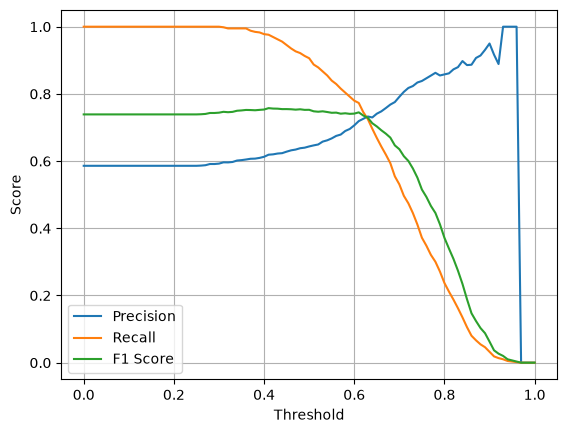

Threshold: 0.63
Precision: 0.733
Recall: 0.725
Max F1 threshold: 0.41
Max F1 score:     0.758
Precision:        0.619
Recall:           0.976


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []
f1_scores = []

y_true = df_val["converted"]
y_scores = model.predict_proba(X_val)[:, 1]

for threshold in thresholds:
    y_pred = (y_scores >= threshold).astype(int)

    precisions.append(
        precision_score(y_true, y_pred, zero_division=0)
    )
    recalls.append(
        recall_score(y_true, y_pred, zero_division=0)
    )
    
    f1_scores.append(f1_score(y_true, y_pred, zero_division=0))

plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.plot(thresholds, f1_scores, label="F1 Score")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

valid = (np.array(precisions) != 0) | (np.array(recalls) != 0)
differences = np.abs(np.array(precisions) - np.array(recalls))

best_idx = np.where(valid)[0][np.argmin(differences[valid])]

print(f"Threshold: {thresholds[best_idx]:.2f}")
print(f"Precision: {precisions[best_idx]:.3f}")
print(f"Recall: {recalls[best_idx]:.3f}")

max_f1_idx = np.argmax(f1_scores)

print(f"Max F1 threshold: {thresholds[max_f1_idx]:.2f}")
print(f"Max F1 score:     {f1_scores[max_f1_idx]:.3f}")
print(f"Precision:        {precisions[max_f1_idx]:.3f}")
print(f"Recall:           {recalls[max_f1_idx]:.3f}")

#### **Question5**

In [38]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)
fold_aucs = []

for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), start=1):
    train_df = df_full_train.iloc[train_idx].copy()
    val_df = df_full_train.iloc[val_idx].copy()

    X_fold_train, X_fold_val = make_features(train_df, val_df)

    model = LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000,
    )
    model.fit(X_fold_train, train_df["converted"])

    val_scores = model.predict_proba(X_fold_val)[:, 1]
    auc = roc_auc_score(val_df["converted"], val_scores)
    fold_aucs.append(auc)

    print(f"Fold {fold}: AUC = {auc:.3f}")

print(f"Mean AUC: {np.mean(fold_aucs):.3f}")
print(f"Standard deviation: {np.std(fold_aucs):.3f}")

NameError: name 'make_features' is not defined

#### **Question6**

In [36]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.sparse import hstack

kf = KFold(n_splits=5, shuffle=True, random_state=1)

C_values = [0.000001, 0.001, 1]
auc_scores = {}

for fold, (train_idx, valid_idx) in enumerate(
    kf.split(df_full_train), start=1
):
    train_df = df_full_train.iloc[train_idx].copy()
    val_df = df_full_train.iloc[valid_idx].copy()

    train_df[categorical_columns] = train_df[categorical_columns].astype(str)
    val_df[categorical_columns] = val_df[categorical_columns].astype(str)

    dv = DictVectorizer()
    X_train_cat = dv.fit_transform(
        train_df[categorical_columns].to_dict(orient="records")
    )
    X_val_cat = dv.transform(
        val_df[categorical_columns].to_dict(orient="records")
    )

    X_train_num = train_df[numerical_columns].values
    X_val_num = val_df[numerical_columns].values

    X_train = hstack([X_train_num, X_train_cat]).tocsr()
    X_val = hstack([X_val_num, X_val_cat]).tocsr()

    for C in C_values:
        model = LogisticRegression(
            solver="liblinear", C=C, max_iter=1000
        )
        model.fit(X_train, train_df["converted"])

        y_val_score = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(val_df["converted"], y_val_score)
        auc_scores[(fold, C)] = auc

# C별 5개 fold 평균 AUC 출력
mean_auc_by_C = {}

for C in C_values:
    scores = [auc_scores[(fold, C)] for fold in range(1, 6)]
    mean_auc_by_C[C] = np.mean(scores)
    print(f"C={C}: mean AUC={np.mean(scores):.3f}, std={np.std(scores):.3f}")

best_C = max(mean_auc_by_C, key=mean_auc_by_C.get)
print(f"\nBest C: {best_C}")

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007

Best C: 0.001
